# 유재윤 RNN 구현과 검증

실제 저장 모델과 validation만 사용한다. 공식 test는 읽지 않는다. `RNN_TRAINING_PROTOCOL_KO.md`와 결과 보고서를 함께 확인한다.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json, csv
import numpy as np
from IPython.display import display, Image
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.runtime import configure_runtime
configure_runtime(2026)
from src.adapters.processed_npz import load_processed_data
from src.models import build_rnn
data = load_processed_data(ROOT/'data/processed_data.npz', ROOT/'data/preprocess.npz')
print('fit',data.x_fit.shape,'validation',data.x_validation.shape)
print('test arrays loaded:',data.provenance['test_arrays_loaded'])
build_rnn().summary()

fit (5577, 128, 9) validation (1775, 128, 9)
test arrays loaded: False


Model: "sequence_rnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,542 (6.02 KB)

 Trainable params: 1,542 (6.02 KB)

 Non-trainable params: 0 (0.00 B)

## 시간 상태와 역전파

$h_t=\tanh(x_tW_x+h_{t-1}W_h+b)$, $z=h_{128}W_o+b_o$. 구간마다 $h_0=0$이다. 작은 RNN의 수치미분은 계산 정확성을 확인하며 장기 기억 능력을 입증하지 않는다.

In [2]:
math = json.loads((ROOT/'reports/rnn/math_verification.json').read_text())
print(math)
analysis = json.loads((ROOT/'reports/rnn/analysis.json').read_text())
for row in analysis['summary']: print(row)
print('Selected RNN', analysis['selected_rnn'])

{'passed': True, 'checked_parameters': 30, 'dtype': 'float64', 'timesteps': 4, 'hidden_units': 3, 'classes': 3, 'finite_difference_step': 1e-05, 'loss': 1.0794872587370854, 'max_absolute_error': 1.8750136859813082e-11, 'max_relative_error': 6.211167753325299e-09, 'scope': 'tiny explicit tanh RNN equation; not a long-memory test'}
{'experiment': 'C01', 'model': 'cnn', 'n': 3, 'parameters': 14054, 'accuracy_mean': 0.8792488262910799, 'accuracy_sd': 0.00676838358345168, 'macro_f1_mean': 0.8783537176514722, 'macro_f1_sd': 0.007257220172264546}
{'experiment': 'L01', 'model': 'lstm', 'n': 3, 'parameters': 21222, 'accuracy_mean': 0.8831924882629107, 'accuracy_sd': 0.019396433928526368, 'macro_f1_mean': 0.8812711970867758, 'macro_f1_sd': 0.01949949659907746}
{'experiment': 'M01', 'model': 'mlp', 'n': 3, 'parameters': 156230, 'accuracy_mean': 0.8666666666666667, 'accuracy_sd': 0.011687029395306407, 'macro_f1_mean': 0.8646071631966787, 'macro_f1_sd': 0.012469865805345993}
{'experiment': 'R01', '

{'accuracy': 0.7301408450704225, 'macro_f1': 0.7063024575949668, 'recall_per_class': [0.4782608695652174, 0.92578125, 0.3278008298755187, 0.6407766990291263, 0.9418960244648318, 1.0], 'confusion_matrix': [[154, 143, 25, 0, 0, 0], [10, 237, 9, 0, 0, 0], [45, 116, 79, 1, 0, 0], [1, 1, 0, 198, 109, 0], [0, 6, 0, 13, 308, 0], [0, 0, 0, 0, 0, 320]]}


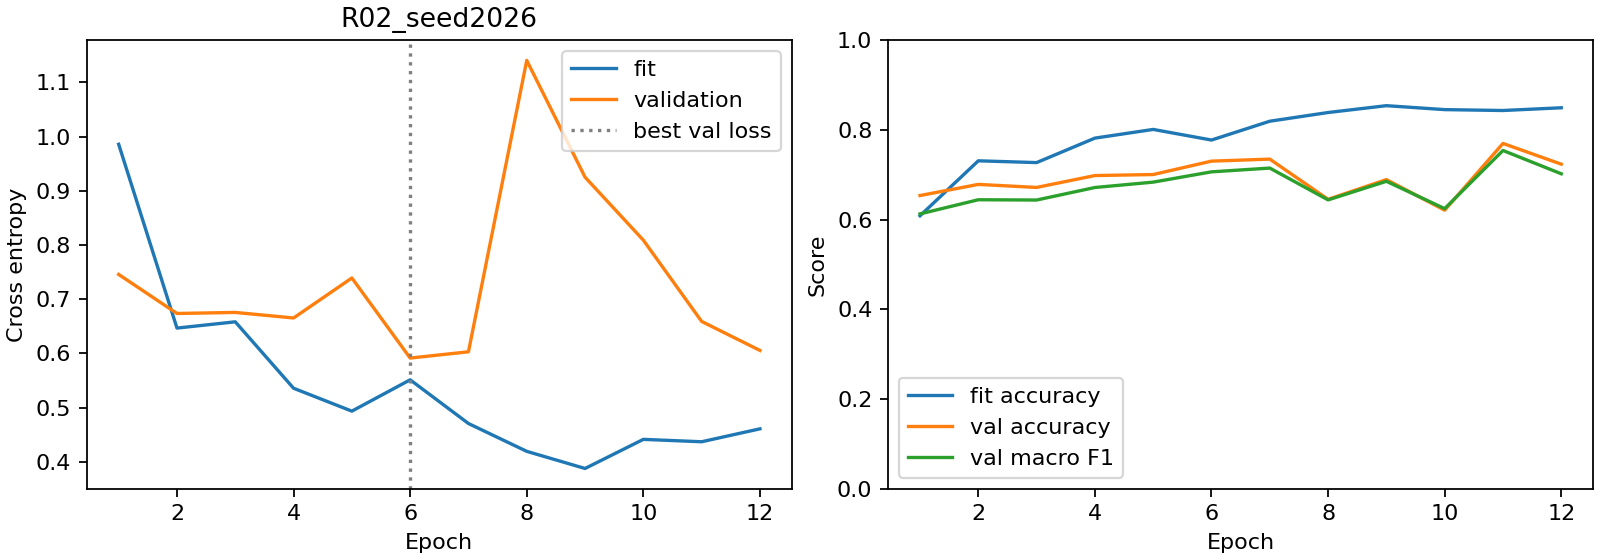

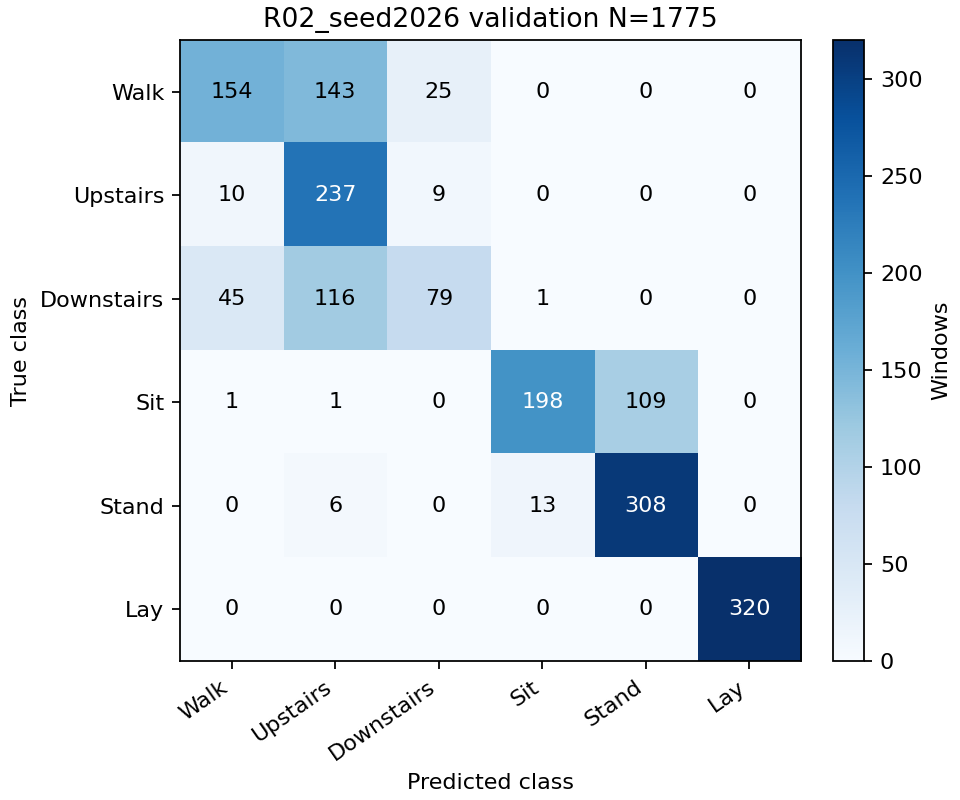

In [3]:
chosen = analysis['selected_rnn']
run = ROOT/'runs/rnn'/f'{chosen}_seed2026'
from tensorflow import keras
from src.train import predict_batches
from src.training_metrics import classification_metrics, softmax
model = keras.models.load_model(run/'model.keras', compile=False)
logits = predict_batches(model,data.x_validation)
print(classification_metrics(data.y_validation,logits))
display(Image(filename=str(ROOT/'reports/rnn/figures'/f'{chosen}_seed2026_history.png')))
display(Image(filename=str(ROOT/'reports/rnn/figures'/f'{chosen}_seed2026_confusion.png')))

validation errors 479
train:000079 1 0 2 0.5173476656212171
train:000081 1 0 2 0.3638091254871431
train:000082 1 0 1 0.6225086781498187
train:000085 1 0 2 0.5038306206215132
train:000086 1 0 1 0.4648198239526647
train:000087 1 0 2 0.43424905203210434
train:000090 1 0 1 0.5341017178902054
train:000092 1 0 1 0.3935613110968876
train:000093 1 0 2 0.40901043547213795
train:000097 1 0 1 0.45390722290421637


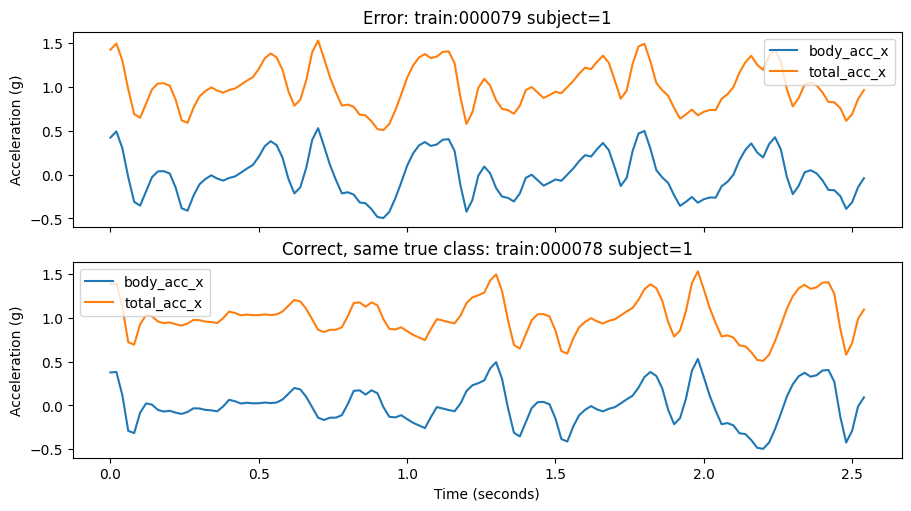

In [4]:
prediction = logits.argmax(1)
wrong = np.flatnonzero(prediction != data.y_validation)
print('validation errors',len(wrong))
for i in wrong[:10]: print(data.validation_ids[i],int(data.validation_subjects[i]),int(data.y_validation[i]),int(prediction[i]),float(softmax(logits[i:i+1]).max()))
import matplotlib.pyplot as plt
if len(wrong):
    bad = wrong[0]
    good = np.flatnonzero((data.y_validation==data.y_validation[bad]) & (prediction==data.y_validation))[0]
    fig,ax=plt.subplots(2,1,figsize=(9,5),sharex=True,layout='constrained')
    for panel,index,title in [(ax[0],bad,'Error'),(ax[1],good,'Correct, same true class')]:
        panel.plot(np.arange(128)/50,data.raw_validation[index,:,0],label='body_acc_x')
        panel.plot(np.arange(128)/50,data.raw_validation[index,:,6],label='total_acc_x')
        panel.set(title=f'{title}: {data.validation_ids[index]} subject={data.validation_subjects[index]}',ylabel='Acceleration (g)')
        panel.legend()
    ax[1].set_xlabel('Time (seconds)')
    plt.show()

## 해석 범위

validation은 조기 종료와 구성 선택에 사용했다. seed SD는 고정 사람 분할에서의 학습 변동이다. 파형 두 사례만으로 오류 원인을 확정하지 않는다. test 평가와 다른 피험자 분할은 후속 작업이다.